# CNN 图像分类实验运行代码（PaddlePaddle + MNIST）
完成：数据准备、网络配置、CNN 定义、损失函数与优化器、训练、评估、预测、曲线绘制、优化器与学习率对比。

> 运行环境：百度 AI Studio Notebook / 本地 Python + PaddlePaddle。  
> 说明：评估准确率时必须把 `label` reshape 成 `[-1]`，避免 `[N]` 与 `[N,1]` 广播导致准确率出现 7.x 这类异常值。


In [2]:
# ======================
# 0. 导入依赖与环境设置
# ======================
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import paddle
import paddle.nn as nn
import paddle.nn.functional as F
from paddle.io import DataLoader
from paddle.vision.datasets import MNIST
from paddle.vision.transforms import Compose, Normalize

# 固定随机种子，便于复现实验
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
paddle.seed(SEED)

# 输出目录：曲线图、预测图、模型参数会保存到这里
SAVE_DIR = "./cnn_mnist_outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

# 自动选择设备：AI Studio 有 GPU 时会使用 GPU，否则使用 CPU
device = "gpu" if paddle.is_compiled_with_cuda() else "cpu"
paddle.set_device(device)
print("PaddlePaddle 版本：", paddle.__version__)
print("当前运行设备：", paddle.device.get_device())
print("输出目录：", os.path.abspath(SAVE_DIR))


PaddlePaddle 版本： 3.3.0
当前运行设备： cpu
输出目录： d:\作业\ai作业\feijiang\cnn_mnist_outputs


## 1. 准备数据
读取 MNIST 训练集和测试集，完成归一化，并显示一张样例图片。

训练样本数： 60000
测试样本数： 10000
单张图片 shape： (1, 28, 28)
样例标签： [5]


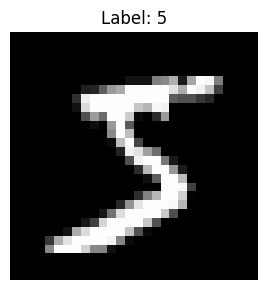

In [ ]:
# ======================
# 1. 准备数据：MNIST + 归一化
# ======================
BATCH_SIZE = 64

# MNIST 像素范围为 0~255，Normalize(mean=127.5, std=127.5) 后约映射到 [-1, 1]
transform = Compose([
    Normalize(mean=[127.5], std=[127.5], data_format="CHW")
])

train_dataset = MNIST(mode="train", transform=transform)
test_dataset = MNIST(mode="test", transform=transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# 查看数据基本信息
sample_img, sample_label = train_dataset[0]
print("训练样本数：", len(train_dataset))
print("测试样本数：", len(test_dataset))
print("单张图片 shape：", np.array(sample_img).shape)
print("样例标签：", np.array(sample_label).reshape(-1))

plt.figure(figsize=(3, 3))
plt.imshow(np.array(sample_img).squeeze(), cmap="gray")
plt.title(f"Label: {int(np.array(sample_label).reshape(-1)[0])}")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "sample_image.png"), dpi=150)
plt.show()


## 2. 网络定义
包含普通全连接基线模型和本实验最终使用的 CNN 模型。

In [ ]:
# ======================
# 2. 定义网络：全连接基线模型与 CNN 模型
# ======================

class FCNet(nn.Layer):
    """普通全连接网络：作为 CNN 的对照组。"""
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(28 * 28, 10)

    def forward(self, x):
        x = paddle.flatten(x, start_axis=1)
        return self.fc(x)


class CNN_MNIST(nn.Layer):
    """
    输入：N x 1 x 28 x 28
    conv1: 16 个 3x3 卷积核，输出 N x 16 x 26 x 26
    pool1: 2x2 最大池化，输出 N x 16 x 13 x 13
    conv2: 32 个 3x3 卷积核，输出 N x 32 x 11 x 11
    pool2: 2x2 最大池化，输出 N x 32 x 5 x 5   
    Flatten: 32*5*5 = 800
    输出：10 类数字
    """
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2D(in_channels=1, out_channels=16, kernel_size=3)
        self.pool = nn.MaxPool2D(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2D(in_channels=16, out_channels=32, kernel_size=3)
        self.fc1 = nn.Linear(32 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = paddle.flatten(x, start_axis=1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


def show_cnn_shapes():
    """打印 CNN 各层输出尺寸，便于理解卷积、池化、全连接之间的关系。"""
    model = CNN_MNIST()
    x = paddle.randn([1, 1, 28, 28])
    print(model)
    print("输入：", x.shape)
    x = model.conv1(x)
    print("conv1 输出：", x.shape)
    x = model.pool(F.relu(x))
    print("pool1 输出：", x.shape)
    x = model.conv2(x)
    print("conv2 输出：", x.shape)
    x = model.pool(F.relu(x))
    print("pool2 输出：", x.shape)
    x = paddle.flatten(x, start_axis=1)
    print("flatten 输出：", x.shape)
    x = F.relu(model.fc1(x))
    print("fc1 输出：", x.shape)
    x = model.fc2(x)
    print("fc2 分类输出：", x.shape)


show_cnn_shapes()


CNN_MNIST(
  (conv1): Conv2D(1, 16, kernel_size=[3, 3], data_format=NCHW)
  (pool): MaxPool2D(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2D(16, 32, kernel_size=[3, 3], data_format=NCHW)
  (fc1): Linear(in_features=800, out_features=128, dtype=float32)
  (fc2): Linear(in_features=128, out_features=10, dtype=float32)
)
输入： paddle.Size([1, 1, 28, 28])
conv1 输出： paddle.Size([1, 16, 26, 26])
pool1 输出： paddle.Size([1, 16, 13, 13])
conv2 输出： paddle.Size([1, 32, 11, 11])
pool2 输出： paddle.Size([1, 32, 5, 5])
flatten 输出： paddle.Size([1, 800])
fc1 输出： paddle.Size([1, 128])
fc2 分类输出： paddle.Size([1, 10])


## 3. 损失函数、优化算法、训练与评估
交叉熵用于多分类，优化器支持 SGD、RMSprop、Adam。

In [5]:
# ======================
# 3. 定义损失函数、优化算法、训练与评估函数
# ======================

def reshape_label(label):
    """修正标签维度：避免 [N] 与 [N,1] 广播造成准确率异常。"""
    return paddle.reshape(label, [-1]).astype("int64")


def build_optimizer(name, learning_rate, parameters, weight_decay=0.0):
    """根据名称创建优化器，支持 SGD / RMSprop / Adam。"""
    regularizer = paddle.regularizer.L2Decay(weight_decay) if weight_decay > 0 else None
    name = name.lower()

    if name == "sgd":
        return paddle.optimizer.SGD(
            learning_rate=learning_rate,
            parameters=parameters,
            weight_decay=regularizer
        )
    elif name == "rmsprop":
        return paddle.optimizer.RMSProp(
            learning_rate=learning_rate,
            parameters=parameters,
            weight_decay=regularizer
        )
    elif name == "adam":
        return paddle.optimizer.Adam(
            learning_rate=learning_rate,
            parameters=parameters,
            weight_decay=regularizer
        )
    else:
        raise ValueError("optimizer_name 只能为 'sgd'、'rmsprop' 或 'adam'")


@paddle.no_grad()
def evaluate(model, data_loader):
    """在测试集或训练集上计算平均 loss 与 accuracy。"""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for img, label in data_loader:
        label = reshape_label(label)
        logits = model(img.astype("float32"))
        loss = F.cross_entropy(logits, label, reduction="mean")
        pred_label = paddle.argmax(logits, axis=1)

        correct += (pred_label == label).astype("int64").sum().item()
        total += label.shape[0]
        total_loss += loss.item()

    avg_loss = total_loss / len(data_loader)
    acc = correct / total
    return avg_loss, acc


def train_model(
    model,
    train_loader,
    test_loader,
    epochs=5,
    optimizer_name="adam",
    learning_rate=0.001,
    weight_decay=0.0,
    max_train_batches=None,
    verbose=True
):
    """
    完整训练流程：
    前向传播 -> 计算交叉熵损失 -> 反向传播 -> 参数更新 -> 每轮评估。
    max_train_batches 用于调参快速对比；最终训练建议设为 None。
    """
    optimizer = build_optimizer(
        optimizer_name, learning_rate, model.parameters(), weight_decay
    )
    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for batch_id, (img, label) in enumerate(train_loader):
            if max_train_batches is not None and batch_id >= max_train_batches:
                break

            label = reshape_label(label)
            logits = model(img.astype("float32"))
            loss = F.cross_entropy(logits, label, reduction="mean")

            loss.backward()
            optimizer.step()
            optimizer.clear_grad()

            pred_label = paddle.argmax(logits, axis=1)
            correct += (pred_label == label).astype("int64").sum().item()
            total += label.shape[0]
            total_loss += loss.item()

            if verbose and batch_id % 200 == 0:
                print(
                    f"Epoch {epoch}/{epochs} | Batch {batch_id:04d} | "
                    f"Loss {loss.item():.4f}"
                )

        train_loss = total_loss / (batch_id + 1)
        train_acc = correct / total
        test_loss, test_acc = evaluate(model, test_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch}/{epochs} 完成 | "
            f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
            f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}"
        )

    return history


## 4. 普通全连接网络对照实验

In [6]:
# ======================
# 4. 对照实验：普通全连接网络
# ======================
# 作用：普通全连接网络会丢失图像二维空间结构，作为 CNN 的对比基线。

fc_model = FCNet()
fc_history = train_model(
    fc_model,
    train_loader,
    test_loader,
    epochs=3,
    optimizer_name="sgd",
    learning_rate=0.01,
    weight_decay=0.0,
    max_train_batches=None,
    verbose=False
)

print("全连接网络最终测试准确率：", f"{fc_history['test_acc'][-1]:.4f}")


Epoch 1/3 完成 | Train Loss: 0.6365, Train Acc: 0.8256 | Test Loss: 0.4044, Test Acc: 0.8859
Epoch 2/3 完成 | Train Loss: 0.3939, Train Acc: 0.8888 | Test Loss: 0.3493, Test Acc: 0.9023
Epoch 3/3 完成 | Train Loss: 0.3581, Train Acc: 0.8977 | Test Loss: 0.3287, Test Acc: 0.9085
全连接网络最终测试准确率： 0.9085


## 5. CNN 模型训练

In [7]:
# ======================
# 5. 训练最终 CNN 模型：Adam + lr=0.001
# ======================

cnn_model = CNN_MNIST()
cnn_history = train_model(
    cnn_model,
    train_loader,
    test_loader,
    epochs=5,
    optimizer_name="adam",
    learning_rate=0.001,
    weight_decay=0.0,
    max_train_batches=None,
    verbose=True
)

# 保存模型参数，提交源码或后续预测时可复用
model_path = os.path.join(SAVE_DIR, "cnn_mnist_final.pdparams")
paddle.save(cnn_model.state_dict(), model_path)
print("CNN 模型参数已保存：", model_path)
print("CNN 最终测试准确率：", f"{cnn_history['test_acc'][-1]:.4f}")


Epoch 1/5 | Batch 0000 | Loss 2.9337
Epoch 1/5 | Batch 0200 | Loss 0.0327
Epoch 1/5 | Batch 0400 | Loss 0.0628
Epoch 1/5 | Batch 0600 | Loss 0.0442
Epoch 1/5 | Batch 0800 | Loss 0.1850
Epoch 1/5 完成 | Train Loss: 0.1615, Train Acc: 0.9504 | Test Loss: 0.0565, Test Acc: 0.9807
Epoch 2/5 | Batch 0000 | Loss 0.0180
Epoch 2/5 | Batch 0200 | Loss 0.0484
Epoch 2/5 | Batch 0400 | Loss 0.0111
Epoch 2/5 | Batch 0600 | Loss 0.0232
Epoch 2/5 | Batch 0800 | Loss 0.0502
Epoch 2/5 完成 | Train Loss: 0.0530, Train Acc: 0.9838 | Test Loss: 0.0440, Test Acc: 0.9857
Epoch 3/5 | Batch 0000 | Loss 0.0213
Epoch 3/5 | Batch 0200 | Loss 0.0074
Epoch 3/5 | Batch 0400 | Loss 0.0383
Epoch 3/5 | Batch 0600 | Loss 0.0381
Epoch 3/5 | Batch 0800 | Loss 0.0118
Epoch 3/5 完成 | Train Loss: 0.0356, Train Acc: 0.9888 | Test Loss: 0.0363, Test Acc: 0.9888
Epoch 4/5 | Batch 0000 | Loss 0.0788
Epoch 4/5 | Batch 0200 | Loss 0.0053
Epoch 4/5 | Batch 0400 | Loss 0.0222
Epoch 4/5 | Batch 0600 | Loss 0.0379
Epoch 4/5 | Batch 0800 |

## 6. 绘制 Loss 和 Accuracy 曲线

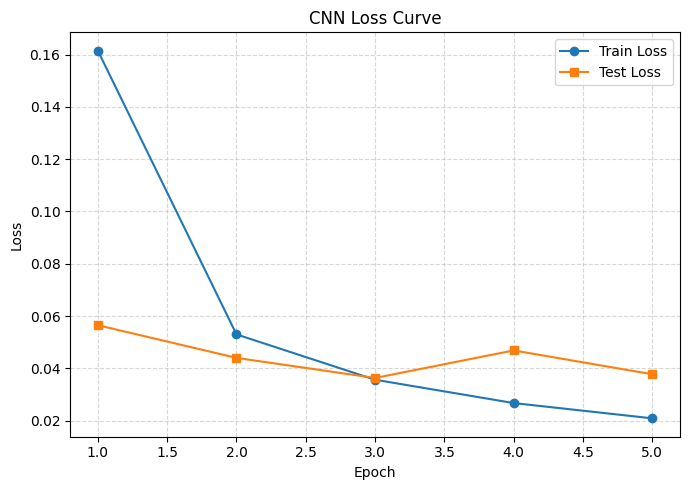

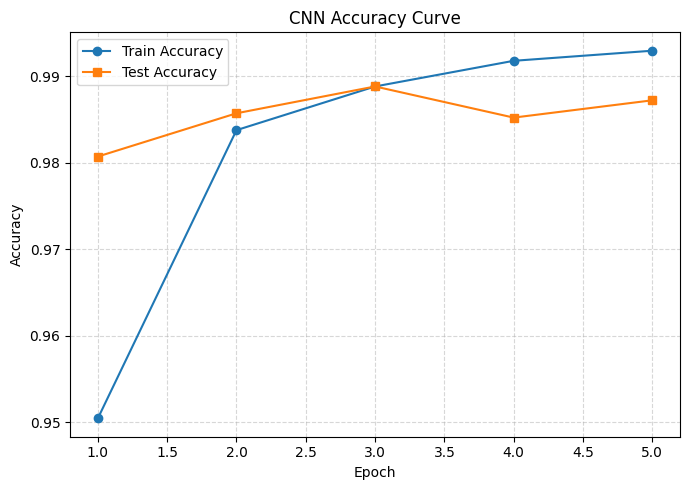

Loss 曲线已保存： ./cnn_mnist_outputs\cnn_loss_curve.png
Accuracy 曲线已保存： ./cnn_mnist_outputs\cnn_accuracy_curve.png


In [8]:
# ======================
# 6. 绘制训练曲线：Loss 与 Accuracy
# ======================

epochs = np.arange(1, len(cnn_history["train_loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs, cnn_history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, cnn_history["test_loss"], marker="s", label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss Curve")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
loss_fig_path = os.path.join(SAVE_DIR, "cnn_loss_curve.png")
plt.savefig(loss_fig_path, dpi=150)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(epochs, cnn_history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, cnn_history["test_acc"], marker="s", label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy Curve")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
acc_fig_path = os.path.join(SAVE_DIR, "cnn_accuracy_curve.png")
plt.savefig(acc_fig_path, dpi=150)
plt.show()

print("Loss 曲线已保存：", loss_fig_path)
print("Accuracy 曲线已保存：", acc_fig_path)


## 7. 优化器与学习率对比


开始对比实验： SGD_lr0.01
Epoch 1/2 完成 | Train Loss: 0.5848, Train Acc: 0.8258 | Test Loss: 0.2583, Test Acc: 0.9267
Epoch 2/2 完成 | Train Loss: 0.2300, Train Acc: 0.9313 | Test Loss: 0.1828, Test Acc: 0.9459

开始对比实验： RMSprop_lr0.001
Epoch 1/2 完成 | Train Loss: 0.3211, Train Acc: 0.9053 | Test Loss: 0.1056, Test Acc: 0.9671
Epoch 2/2 完成 | Train Loss: 0.0860, Train Acc: 0.9732 | Test Loss: 0.0711, Test Acc: 0.9764

开始对比实验： Adam_lr0.01
Epoch 1/2 完成 | Train Loss: 0.7122, Train Acc: 0.7927 | Test Loss: 0.2261, Test Acc: 0.9283
Epoch 2/2 完成 | Train Loss: 0.2507, Train Acc: 0.9223 | Test Loss: 0.1967, Test Acc: 0.9358

开始对比实验： Adam_lr0.001
Epoch 1/2 完成 | Train Loss: 0.3354, Train Acc: 0.8980 | Test Loss: 0.1084, Test Acc: 0.9678
Epoch 2/2 完成 | Train Loss: 0.1046, Train Acc: 0.9683 | Test Loss: 0.0852, Test Acc: 0.9735

开始对比实验： Adam_lr0.0001
Epoch 1/2 完成 | Train Loss: 0.8957, Train Acc: 0.7409 | Test Loss: 0.3211, Test Acc: 0.9160
Epoch 2/2 完成 | Train Loss: 0.2551, Train Acc: 0.9285 | Test Loss: 0.18

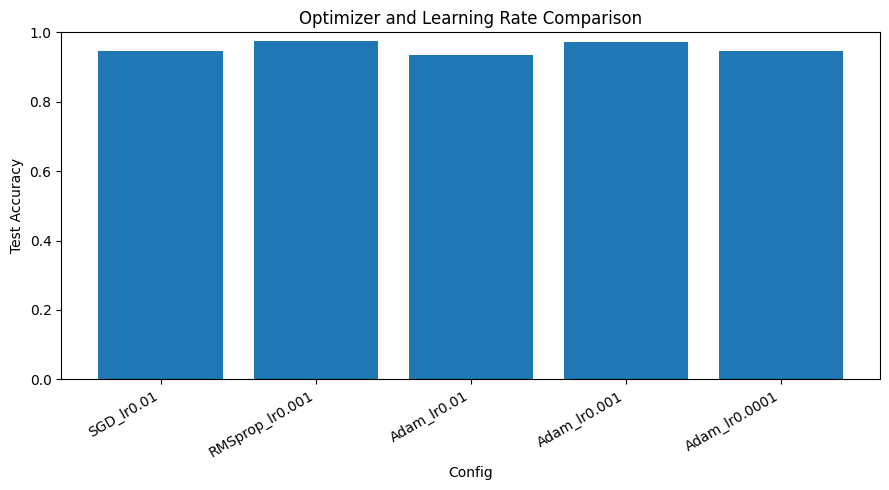

调参对比图已保存： ./cnn_mnist_outputs\optimizer_lr_compare.png


In [9]:
# ======================
# 7. 调参实验：优化器与学习率快速对比
# ======================
# 为了节省时间，这里每组只训练 2 个 epoch，且每轮最多使用 300 个 batch。
# 如果时间充足，可把 max_train_batches=None、epochs 调大，得到更稳定结果。

compare_configs = [
    {"name": "SGD_lr0.01",     "optimizer": "sgd",     "lr": 0.01},
    {"name": "RMSprop_lr0.001","optimizer": "rmsprop", "lr": 0.001},
    {"name": "Adam_lr0.01",    "optimizer": "adam",    "lr": 0.01},
    {"name": "Adam_lr0.001",   "optimizer": "adam",    "lr": 0.001},
    {"name": "Adam_lr0.0001",  "optimizer": "adam",    "lr": 0.0001},
]

compare_results = []
for cfg in compare_configs:
    print("\n" + "=" * 60)
    print("开始对比实验：", cfg["name"])
    temp_model = CNN_MNIST()
    temp_history = train_model(
        temp_model,
        train_loader,
        test_loader,
        epochs=2,
        optimizer_name=cfg["optimizer"],
        learning_rate=cfg["lr"],
        weight_decay=0.0,
        max_train_batches=300,
        verbose=False
    )
    compare_results.append({
        "配置": cfg["name"],
        "优化器": cfg["optimizer"],
        "学习率": cfg["lr"],
        "测试Loss": temp_history["test_loss"][-1],
        "测试准确率": temp_history["test_acc"][-1],
    })

print("\n优化器与学习率对比结果：")
for row in compare_results:
    print(
        f"{row['配置']:<18} | Loss: {row['测试Loss']:.4f} | "
        f"Acc: {row['测试准确率']:.4f}"
    )

# 画对比柱状图
names = [r["配置"] for r in compare_results]
accs = [r["测试准确率"] for r in compare_results]

plt.figure(figsize=(9, 5))
plt.bar(names, accs)
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.0)
plt.xlabel("Config")
plt.ylabel("Test Accuracy")
plt.title("Optimizer and Learning Rate Comparison")
plt.tight_layout()
compare_fig_path = os.path.join(SAVE_DIR, "optimizer_lr_compare.png")
plt.savefig(compare_fig_path, dpi=150)
plt.show()

print("调参对比图已保存：", compare_fig_path)


## 8. 模型评估与单张图片预测

最终测试集 Loss：0.0377
最终测试集 Accuracy：0.9872


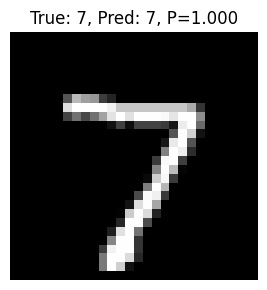

单张图片预测结果
样本序号： 0
真实标签： 7
预测标签： 7
预测概率： 1.0000
预测图已保存： ./cnn_mnist_outputs\prediction_index_0.png


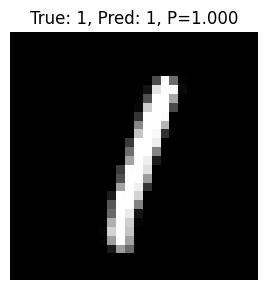

单张图片预测结果
样本序号： 5
真实标签： 1
预测标签： 1
预测概率： 1.0000
预测图已保存： ./cnn_mnist_outputs\prediction_index_5.png


In [10]:
# ======================
# 8. 模型评估与单张图片预测
# ======================

final_test_loss, final_test_acc = evaluate(cnn_model, test_loader)
print(f"最终测试集 Loss：{final_test_loss:.4f}")
print(f"最终测试集 Accuracy：{final_test_acc:.4f}")

@paddle.no_grad()
def predict_one(model, dataset, index=0):
    """随机或指定一张测试集图片进行预测，并显示结果。"""
    model.eval()
    img, label = dataset[index]
    true_label = int(np.array(label).reshape(-1)[0])

    input_img = paddle.to_tensor(np.array(img)).astype("float32")
    if len(input_img.shape) == 3:
        input_img = paddle.unsqueeze(input_img, axis=0)

    logits = model(input_img)
    prob = F.softmax(logits, axis=1)
    pred_label = int(paddle.argmax(prob, axis=1).item())
    pred_prob = float(prob[0][pred_label].item())

    plt.figure(figsize=(3, 3))
    plt.imshow(np.array(img).squeeze(), cmap="gray")
    plt.title(f"True: {true_label}, Pred: {pred_label}, P={pred_prob:.3f}")
    plt.axis("off")
    plt.tight_layout()
    pred_fig_path = os.path.join(SAVE_DIR, f"prediction_index_{index}.png")
    plt.savefig(pred_fig_path, dpi=150)
    plt.show()

    print("单张图片预测结果")
    print("样本序号：", index)
    print("真实标签：", true_label)
    print("预测标签：", pred_label)
    print("预测概率：", f"{pred_prob:.4f}")
    print("预测图已保存：", pred_fig_path)

# 可修改 index 查看不同测试图片
predict_one(cnn_model, test_dataset, index=0)
predict_one(cnn_model, test_dataset, index=5)


## 9. 结果汇总

In [11]:
# ======================
# 9. 结果汇总
# ======================

summary_rows = [
    {
        "实验模型/配置": "普通全连接网络",
        "主要设置": "Flatten + Linear + SGD(lr=0.01)",
        "测试准确率": fc_history["test_acc"][-1],
        "现象分析": "结构简单，未充分利用图像空间信息"
    },
    {
        "实验模型/配置": "改进 CNN",
        "主要设置": "Conv2D + ReLU + MaxPool + FC + Adam(lr=0.001)",
        "测试准确率": cnn_history["test_acc"][-1],
        "现象分析": "能提取局部笔画和形状特征，准确率更高"
    }
]

print("核心结果汇总：")
for row in summary_rows:
    print(
        f"{row['实验模型/配置']} | {row['主要设置']} | "
        f"测试准确率：{row['测试准确率']:.4f} | {row['现象分析']}"
    )

print("\n调参结果可参考 compare_results：")
for row in compare_results:
    print(f"{row['配置']}：Acc={row['测试准确率']:.4f}, Loss={row['测试Loss']:.4f}")



核心结果汇总：
普通全连接网络 | Flatten + Linear + SGD(lr=0.01) | 测试准确率：0.9085 | 结构简单，未充分利用图像空间信息
改进 CNN | Conv2D + ReLU + MaxPool + FC + Adam(lr=0.001) | 测试准确率：0.9872 | 能提取局部笔画和形状特征，准确率更高

调参结果可参考 compare_results：
SGD_lr0.01：Acc=0.9459, Loss=0.1828
RMSprop_lr0.001：Acc=0.9764, Loss=0.0711
Adam_lr0.01：Acc=0.9358, Loss=0.1967
Adam_lr0.001：Acc=0.9735, Loss=0.0852
Adam_lr0.0001：Acc=0.9469, Loss=0.1893
